# Used Car Price Analysis (India)

**Tools:** Python (Pandas, NumPy, SciPy), SQL (SQLite), Matplotlib, Seaborn, Plotly

**Dataset:** CarDekho used car listings from India (file `cardekho_dataset.csv`, 15,411 rows, 14 columns). Each row is one used car for sale: brand, model, age, kilometres driven, fuel, transmission, seller type, engine size, power, mileage and the selling price in rupees.

**What I want to find out**
1. How fast do used cars lose value?
2. What matters most for the price: age, kilometres, engine power or something else?
3. Do automatic cars, diesel cars and dealer listings really cost more, or is that only because they are different cars?
4. Which brands and models hold their value best?

**How the notebook is organised**
1. Load the data and look at it
2. Check data quality with SQL
3. Clean the data (every step is logged)
4. Answer business questions with SQL
5. Deeper analysis in Python (value loss per year, fair comparisons)
6. Charts, including scatter plots
7. Findings
8. Save the cleaned files

In [1]:
import os, json
import numpy as np
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import spearmanr

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

os.makedirs("charts", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

## 1. Load the data

In [2]:
DATA_PATH = "cardekho_dataset.csv"   # see the README for the source

raw = pd.read_csv(DATA_PATH)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (15411, 14)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"15,411.00","9,811.86","5,643.42",0.00,"4,906.50","9,872.00","14,668.50","19,543.00"
vehicle_age,"15,411.00",6.04,3.01,0.00,4.00,6.00,8.00,29.00
km_driven,"15,411.00","55,616.48","51,618.55",100.00,"30,000.00","50,000.00","70,000.00","3,800,000.00"
mileage,"15,411.00",19.70,4.17,4.00,17.00,19.67,22.70,33.54
engine,"15,411.00","1,486.06",521.11,793.00,"1,197.00","1,248.00","1,582.00","6,592.00"
max_power,"15,411.00",100.59,42.97,38.40,74.00,88.50,117.30,626.00
seats,"15,411.00",5.33,0.81,0.00,5.00,5.00,5.00,9.00
selling_price,"15,411.00","774,971.12","894,128.36","40,000.00","385,000.00","556,000.00","825,000.00","39,500,000.00"


What I notice at first look:
- The first column `Unnamed: 0` is an old row number, not a feature.
- A few values look wrong: a car with 3.8 million km, cars with 0 seats.
- Prices go up to about ₹3.95 crore (a Ferrari), while the middle car costs about ₹5.6 lakh. The price is very skewed, so I will use the **median** instead of the average and log scales in charts.
- All prices are in rupees. 1 lakh = 100,000 rupees and 1 crore = 100 lakh.

## 2. Check data quality with SQL

I load the raw data into SQLite and count the problems before I change anything.

In [4]:
con = sqlite3.connect(":memory:")
raw.rename(columns={"Unnamed: 0": "listing_index"}).to_sql("raw_cars", con, index=False)

def q(sql):
    return pd.read_sql_query(sql, con)

q('''
SELECT COUNT(*)                                  AS total_rows,
       SUM(seats = 0)                            AS zero_seats,
       SUM(km_driven > 500000)                   AS km_over_500k,
       SUM(selling_price > 10000000)             AS price_over_1_crore,
       SUM(vehicle_age = 0)                      AS age_zero,
       SUM(mileage < 8)                          AS mileage_under_8,
       COUNT(DISTINCT brand)                     AS distinct_brand_spellings
FROM raw_cars
''')

,total_rows,zero_seats,km_over_500k,price_over_1_crore,age_zero,mileage_under_8,distinct_brand_spellings
0,15411,2,12,7,5,11,32


In [5]:
# Exact duplicates: same values in every column except the old row number
q('''
SELECT SUM(cnt - 1) AS extra_duplicate_rows
FROM (
    SELECT COUNT(*) AS cnt
    FROM raw_cars
    GROUP BY car_name, brand, model, vehicle_age, km_driven, seller_type, fuel_type,
             transmission_type, mileage, engine, max_power, seats, selling_price
    HAVING COUNT(*) > 1
)
''')

,extra_duplicate_rows
0,167


In [6]:
# Same brand written in two ways?
q('''
SELECT brand, COUNT(*) AS listings
FROM raw_cars
WHERE LOWER(brand) IN (SELECT LOWER(brand) FROM raw_cars GROUP BY LOWER(brand) HAVING COUNT(DISTINCT brand) > 1)
GROUP BY brand
''')

,brand,listings
0,ISUZU,2
1,Isuzu,8


In [7]:
# Cars labelled Electric
q('''
SELECT car_name, fuel_type, engine, max_power, COUNT(*) AS listings
FROM raw_cars
WHERE fuel_type = 'Electric'
GROUP BY car_name, fuel_type, engine, max_power
''')

,car_name,fuel_type,engine,max_power,listings
0,Toyota Camry,Electric,2494,157.70,4


All 4 "Electric" rows are the Toyota Camry with a 2,494 cc engine. An electric car has no engine size like that, so the label is most likely wrong (probably the Camry Hybrid). I cannot be sure, so I keep these rows but leave them out of every fuel type comparison.

In [8]:
# Mileage by fuel type: CNG and LPG cars are usually measured in km per kg, not km per litre
q('''
SELECT fuel_type, COUNT(*) AS listings, MIN(mileage) AS min_mileage, ROUND(AVG(mileage), 1) AS avg_mileage, MAX(mileage) AS max_mileage
FROM raw_cars
GROUP BY fuel_type
ORDER BY listings DESC
''')

,fuel_type,listings,min_mileage,avg_mileage,max_mileage
0,Petrol,7643,4.00,19.10,28.09
1,Diesel,7419,7.50,20.10,28.40
2,CNG,301,11.88,25.80,33.54
3,LPG,44,13.45,17.80,26.20
4,Electric,4,19.16,19.20,19.16


CNG and LPG mileage is not in the same unit as petrol and diesel, so I only compare mileage for petrol and diesel cars.

## 3. Clean the data

Every step is logged with row counts.

My decisions:
- **Old row number column:** drop it.
- **Brand spelling:** make `ISUZU` and `Isuzu` the same brand.
- **Exact duplicates:** remove. Every column is identical, including mileage and power, so they are almost certainly the same listing added twice. This is an assumption, I cannot be 100% sure.
- **0 seats:** impossible, remove.
- **Impossible kilometres:** a private car driven more than 100,000 km per year is not realistic (the worst one is 3.8 million km on a 5 year old car). I remove those.
- **Very expensive cars (over ₹1 crore):** these are real (Ferrari, Rolls-Royce, Bentley, S-Class). I keep them, but I use medians and log charts so they do not distort the results.
- **Age 0 cars:** real nearly new cars, I keep them.

In [9]:
log = []
def step(name, before, after, changed=0):
    log.append({"step": name, "rows_before": before, "rows_after": after,
                "rows_removed": before - after, "rows_changed": changed})

df = raw.drop(columns="Unnamed: 0").copy()
step("Drop the old row number column", len(df), len(df))

# 1. brand spelling
canon = df.groupby(df["brand"].str.lower())["brand"].agg(lambda s: s.value_counts().index[0])
fixed = df["brand"].str.lower().map(canon)
changed = int((fixed != df["brand"]).sum())
df["brand"] = fixed
df["car_name"] = df["brand"] + " " + df["model"]
step("Make brand spelling consistent (ISUZU and Isuzu)", len(df), len(df), changed)

# 2. duplicates
n = len(df)
df = df.drop_duplicates()
step("Remove exact duplicate rows", n, len(df))

# 3. zero seats
n = len(df)
df = df[df["seats"] > 0]
step("Remove cars with 0 seats", n, len(df))

# 4. impossible kilometres per year
df["km_per_year"] = df["km_driven"] / df["vehicle_age"].clip(lower=1)
n = len(df)
df = df[df["km_per_year"] <= 100_000]
step("Remove cars driven more than 100,000 km per year", n, len(df))

df = df.reset_index(drop=True)
pd.DataFrame(log)

,step,rows_before,rows_after,rows_removed,rows_changed
0,Drop the old row number column,15411,15411,0,0
1,Make brand spelling consistent (ISUZU and Isuzu),15411,15411,0,2
2,Remove exact duplicate rows,15411,15244,167,0
3,Remove cars with 0 seats,15244,15242,2,0
4,"Remove cars driven more than 100,000 km per year",15242,15229,13,0


In [10]:
# New columns
df["price_lakh"] = df["selling_price"] / 100_000
df["age_band"] = pd.cut(df["vehicle_age"], bins=[-1, 2, 5, 8, 100], labels=["0-2", "3-5", "6-8", "9+"])

# Subsets used for fair comparisons
fuel_df = df[df["fuel_type"].isin(["Petrol", "Diesel", "CNG"])]      # Electric rows look mislabelled, LPG is tiny
mileage_df = df[df["fuel_type"].isin(["Petrol", "Diesel"])]           # same unit (km per litre)

print("Clean rows:", len(df))
print("Median price: Rs", f"{df['selling_price'].median():,.0f}", "| Average price: Rs", f"{df['selling_price'].mean():,.0f}")
print("Cars over Rs 1 crore:", int((df['selling_price'] > 10_000_000).sum()))

Clean rows: 15229
Median price: Rs 556,000 | Average price: Rs 774,552
Cars over Rs 1 crore: 7


Now I load the clean table into SQLite for the business questions.

In [11]:
df.drop(columns=["age_band"]).to_sql("cars", con, index=False, if_exists="replace")
q("SELECT COUNT(*) AS clean_rows FROM cars")

,clean_rows
0,15229


## 4. Business questions answered with SQL

SQLite has no `MEDIAN` function. I find the median with `ROW_NUMBER()` and take the middle row (or the average of the two middle rows).

### Q1. How does the median price change with the age of the car?

In [12]:
q('''
WITH ranked AS (
    SELECT vehicle_age, selling_price,
           ROW_NUMBER() OVER (PARTITION BY vehicle_age ORDER BY selling_price) AS rn,
           COUNT(*)     OVER (PARTITION BY vehicle_age)                        AS cnt
    FROM cars
),
med AS (
    SELECT vehicle_age, MAX(cnt) AS listings, AVG(selling_price) AS median_price
    FROM ranked
    WHERE rn IN ((cnt + 1) / 2, (cnt + 2) / 2)
    GROUP BY vehicle_age
)
SELECT vehicle_age, listings, ROUND(median_price, 0) AS median_price,
       ROUND(100.0 * (median_price - LAG(median_price) OVER (ORDER BY vehicle_age))
             / LAG(median_price) OVER (ORDER BY vehicle_age), 1) AS pct_change_vs_previous_age
FROM med
WHERE vehicle_age <= 15
ORDER BY vehicle_age
''')

,vehicle_age,listings,median_price,pct_change_vs_previous_age
0,0,4,"525,000.00",NaN
1,1,220,"750,000.00",42.90
2,2,1133,"816,000.00",8.80
3,3,1896,"748,000.00",-8.30
4,4,2216,"695,500.00",-7.00
5,5,2091,"600,000.00",-13.70
6,6,1901,"550,000.00",-8.30
7,7,1427,"500,000.00",-9.10
8,8,1271,"450,000.00",-10.00
9,9,1014,"400,000.00",-11.10


Age 0 has only 4 listings and age 1 has 220, so I do not read much into those first two rows. From age 2 onwards the median price falls every year. This table still mixes cheap and expensive models, so in Section 5 I compare the same model at different ages, which is fairer.

### Q2. Which brands have the most listings, and what do they cost?

In [13]:
q('''
WITH ranked AS (
    SELECT brand, selling_price,
           ROW_NUMBER() OVER (PARTITION BY brand ORDER BY selling_price) AS rn,
           COUNT(*)     OVER (PARTITION BY brand)                        AS cnt
    FROM cars
),
med AS (
    SELECT brand, MAX(cnt) AS listings, AVG(selling_price) AS median_price
    FROM ranked
    WHERE rn IN ((cnt + 1) / 2, (cnt + 2) / 2)
    GROUP BY brand
)
SELECT m.brand, m.listings, ROUND(m.median_price, 0) AS median_price,
       ROUND(AVG(c.vehicle_age), 1) AS avg_age, ROUND(AVG(c.km_driven), 0) AS avg_km,
       ROUND(100.0 * m.listings / (SELECT COUNT(*) FROM cars), 1) AS pct_of_listings
FROM med m JOIN cars c ON c.brand = m.brand
WHERE m.listings >= 100
GROUP BY m.brand
ORDER BY m.listings DESC
''')

,brand,listings,median_price,avg_age,avg_km,pct_of_listings
0,Maruti,4931,"465,000.00",5.90,"51,219.00",32.40
1,Hyundai,2951,"525,000.00",6.10,"50,084.00",19.40
2,Honda,1474,"590,500.00",6.30,"53,215.00",9.70
3,Mahindra,998,"750,000.00",6.00,"69,341.00",6.60
4,Toyota,787,"1,275,000.00",6.50,"90,118.00",5.20
5,Ford,775,"565,000.00",6.00,"57,471.00",5.10
6,Volkswagen,613,"499,000.00",6.70,"61,614.00",4.00
7,Renault,525,"395,000.00",4.80,"46,081.00",3.40
8,BMW,436,"2,287,500.00",6.60,"51,094.00",2.90
9,Tata,421,"550,000.00",4.30,"47,466.00",2.80


### Q3. How much of its price does a model keep as it gets older?
For each popular model I compare the average price in each age group with the price of the newest age group (0 to 2 years). This uses `FIRST_VALUE`.

In [14]:
q('''
WITH base AS (
    SELECT car_name,
           CASE WHEN vehicle_age <= 2 THEN '0-2' WHEN vehicle_age <= 5 THEN '3-5'
                WHEN vehicle_age <= 8 THEN '6-8' ELSE '9+' END AS age_band,
           selling_price
    FROM cars
),
band_avg AS (
    SELECT car_name, age_band, COUNT(*) AS n, AVG(selling_price) AS avg_price
    FROM base
    GROUP BY car_name, age_band
),
eligible AS (
    SELECT car_name FROM band_avg GROUP BY car_name HAVING COUNT(*) = 4 AND MIN(n) >= 15
),
with_pct AS (
    SELECT b.car_name, b.age_band, b.n, b.avg_price,
           100.0 * b.avg_price / FIRST_VALUE(b.avg_price) OVER (PARTITION BY b.car_name ORDER BY b.age_band) AS pct_of_newest
    FROM band_avg b JOIN eligible e ON e.car_name = b.car_name
)
SELECT car_name, ROUND(avg_price, 0) AS avg_price_9_plus_years, ROUND(pct_of_newest, 0) AS pct_of_price_when_0_to_2_years_old
FROM with_pct
WHERE age_band = '9+'
ORDER BY pct_of_newest DESC
''')

,car_name,avg_price_9_plus_years,pct_of_price_when_0_to_2_years_old
0,Maruti Eeco,"229,850.00",56.00
1,Maruti Ertiga,"517,792.00",54.00
2,Maruti Swift,"314,713.00",50.00
3,Maruti Swift Dzire,"336,342.00",48.00
4,Maruti Alto,"166,915.00",47.00
5,Hyundai i20,"331,273.00",47.00
6,Mahindra Bolero,"351,786.00",46.00
7,Volkswagen Polo,"300,048.00",43.00
8,Mahindra XUV500,"651,250.00",42.00
9,Maruti Wagon R,"194,273.00",39.00


### Q4. Automatic vs manual, for the same model
I only compare models that have at least 50 automatic and 50 manual listings.

In [15]:
# Automatic vs manual for each model, using MEDIAN prices (same method as the headline number)
q('''
WITH ranked AS (
    SELECT car_name, transmission_type, selling_price,
           ROW_NUMBER() OVER (PARTITION BY car_name, transmission_type ORDER BY selling_price) AS rn,
           COUNT(*)     OVER (PARTITION BY car_name, transmission_type)                        AS n
    FROM cars
    WHERE transmission_type IN ('Automatic', 'Manual')
),
m AS (   -- median price of each model for each transmission (models need 50+ listings per transmission)
    SELECT car_name, transmission_type, MAX(n) AS n, AVG(selling_price) AS median_price
    FROM ranked
    WHERE n >= 50 AND rn IN ((n + 1) / 2, (n + 2) / 2)
    GROUP BY car_name, transmission_type
)
SELECT a.car_name, a.n AS automatic_listings, b.n AS manual_listings,
       ROUND(a.median_price, 0) AS automatic_median, ROUND(b.median_price, 0) AS manual_median,
       ROUND(a.median_price / b.median_price, 2) AS automatic_vs_manual
FROM m a JOIN m b ON a.car_name = b.car_name
WHERE a.transmission_type = 'Automatic' AND b.transmission_type = 'Manual'
ORDER BY automatic_vs_manual DESC
''')

,car_name,automatic_listings,manual_listings,automatic_median,manual_median,automatic_vs_manual
0,Toyota Fortuner,85,101,"2,599,000.00","1,400,000.00",1.86
1,Toyota Innova,80,463,"1,795,000.00","975,000.00",1.84
2,Volkswagen Vento,67,178,"645,000.00","400,000.00",1.61
3,Mahindra XUV500,54,272,"1,262,500.00","850,500.00",1.48
4,Maruti Wagon R,64,645,"437,500.00","300,000.00",1.46
5,Honda Amaze,57,303,"675,000.00","465,000.00",1.45
6,Maruti Swift Dzire,90,785,"725,000.00","500,000.00",1.45
7,Volkswagen Polo,67,301,"675,000.00","465,000.00",1.45
8,Skoda Rapid,66,115,"660,000.00","475,000.00",1.39
9,Honda City,136,613,"807,500.00","595,000.00",1.36


In [16]:
# Median of the per-model ratios = the 'same model' price ratio
q('''
WITH ranked AS (
    SELECT car_name, transmission_type, selling_price,
           ROW_NUMBER() OVER (PARTITION BY car_name, transmission_type ORDER BY selling_price) AS rn,
           COUNT(*)     OVER (PARTITION BY car_name, transmission_type)                        AS n
    FROM cars
    WHERE transmission_type IN ('Automatic', 'Manual')
),
m AS (
    SELECT car_name, transmission_type, MAX(n) AS n, AVG(selling_price) AS median_price
    FROM ranked
    WHERE n >= 50 AND rn IN ((n + 1) / 2, (n + 2) / 2)
    GROUP BY car_name, transmission_type
),
r AS (
    SELECT a.median_price / b.median_price AS ratio
    FROM m a JOIN m b ON a.car_name = b.car_name
    WHERE a.transmission_type = 'Automatic' AND b.transmission_type = 'Manual'
),
o AS (
    SELECT ratio, ROW_NUMBER() OVER (ORDER BY ratio) AS rn, COUNT(*) OVER () AS cnt FROM r
)
SELECT MAX(cnt) AS models_compared, ROUND(AVG(ratio), 2) AS median_of_ratios
FROM o
WHERE rn IN ((cnt + 1) / 2, (cnt + 2) / 2)
''')

,models_compared,median_of_ratios
0,16,1.42


### Q5. Price quartiles: what do cheap and expensive cars look like?

In [17]:
q('''
WITH t AS (
    SELECT *, NTILE(4) OVER (ORDER BY selling_price) AS price_quartile
    FROM cars
)
SELECT price_quartile, COUNT(*) AS listings,
       MIN(selling_price) AS min_price, MAX(selling_price) AS max_price,
       ROUND(AVG(vehicle_age), 1) AS avg_age, ROUND(AVG(km_driven), 0) AS avg_km,
       ROUND(AVG(max_power), 0) AS avg_power, ROUND(AVG(engine), 0) AS avg_engine_cc,
       ROUND(100.0 * SUM(transmission_type = 'Automatic') / COUNT(*), 1) AS pct_automatic
FROM t
GROUP BY price_quartile
ORDER BY price_quartile
''')

,price_quartile,listings,min_price,max_price,avg_age,avg_km,avg_power,avg_engine_cc,pct_automatic
0,1,3808,40000,385000,8.50,"62,214.00",73.00,"1,166.00",4.10
1,2,3807,385000,556000,6.10,"56,227.00",87.00,"1,343.00",11.40
2,3,3807,557000,825000,4.80,"51,189.00",94.00,"1,432.00",16.60
3,4,3807,825000,39500000,4.80,"49,938.00",148.00,"2,003.00",50.50


### Q6. Which model is the most expensive in each popular brand?

In [18]:
q('''
WITH model_avg AS (
    SELECT brand, model, COUNT(*) AS n, AVG(selling_price) AS avg_price,
           RANK() OVER (PARTITION BY brand ORDER BY AVG(selling_price) DESC) AS rk
    FROM cars
    WHERE brand IN (SELECT brand FROM cars GROUP BY brand HAVING COUNT(*) >= 300)
    GROUP BY brand, model
    HAVING COUNT(*) >= 10
)
SELECT brand, model, n AS listings, ROUND(avg_price, 0) AS avg_price
FROM model_avg
WHERE rk = 1
ORDER BY avg_price DESC
''')

,brand,model,listings,avg_price
0,Mercedes-Benz,GLS,12,"6,781,083.00"
1,BMW,6,17,"5,069,882.00"
2,Ford,Endeavour,42,"2,118,071.00"
3,Toyota,Fortuner,186,"1,942,677.00"
4,Hyundai,Tucson,10,"1,780,900.00"
5,Tata,Harrier,20,"1,611,950.00"
6,Skoda,Octavia,58,"1,262,241.00"
7,Honda,CR-V,28,"1,247,679.00"
8,Mahindra,Marazzo,24,"1,093,375.00"
9,Maruti,Vitara,289,"830,678.00"


### Q7. How many kilometres per year do owners drive, by fuel type?

In [19]:
q('''
SELECT fuel_type, COUNT(*) AS listings,
       ROUND(AVG(km_driven * 1.0 / MAX(vehicle_age, 1)), 0) AS avg_km_per_year,
       ROUND(AVG(vehicle_age), 1) AS avg_age
FROM cars
GROUP BY fuel_type
ORDER BY listings DESC
''')

,fuel_type,listings,avg_km_per_year,avg_age
0,Petrol,7551,"7,593.00",6.00
1,Diesel,7331,"11,820.00",6.10
2,CNG,299,"10,941.00",5.50
3,LPG,44,"7,134.00",11.10
4,Electric,4,"11,479.00",5.80


## 5. Deeper analysis in Python

### How much value does a car lose per year?
Comparing all cars of one age with all cars of another age mixes cheap and expensive models. A fairer way is to look at **one model at a time**.

For each model with at least 100 listings and at least 5 different ages, I fit a straight line to `log(price)` against `age`. A straight line on the log scale means the price falls by the same **percent** every year. The slope turns directly into "percent of value lost per year".

In [20]:
rows = []
for name, s in df.groupby("car_name"):
    if len(s) >= 100 and s["vehicle_age"].nunique() >= 5:
        slope = np.polyfit(s["vehicle_age"], np.log(s["selling_price"]), 1)[0]
        rows.append({"car_name": name, "listings": len(s), "annual_value_loss_pct": 100 * (1 - np.exp(slope))})

dep = pd.DataFrame(rows).sort_values("annual_value_loss_pct").reset_index(drop=True)
print("Models analysed:", len(dep))
print(f"Median yearly value loss across these models: {dep['annual_value_loss_pct'].median():.1f}%")
dep

Models analysed: 36
Median yearly value loss across these models: 10.6%


,car_name,listings,annual_value_loss_pct
0,Maruti Celerio,234,4.92
1,Maruti Eeco,124,6.78
2,Maruti Vitara,289,7.28
3,Hyundai Grand,569,7.40
4,Hyundai Creta,334,7.51
5,Hyundai i10,406,8.02
6,Maruti Ertiga,341,8.03
7,Maruti Alto,768,8.63
8,Renault KWID,299,8.88
9,Mahindra Bolero,207,8.97


### Are automatic, diesel and dealer cars really more expensive?
First the raw gap: median price of one group divided by the other. Then a fairer gap: for each model that has at least 50 listings in both groups, compare the two groups **within that model**, and take the median of those ratios. This removes the effect of "automatic cars are mostly bigger and pricier models".

This is not a perfect test. Age and kilometres can still differ between the groups, so I call it a closer comparison, not proof of cause.

In [21]:
def same_model_gap(data, col, a, b, min_n=50):
    t = data.groupby(["car_name", col])["selling_price"].agg(["count", "median"]).unstack()
    ok = t[(t[("count", a)] >= min_n) & (t[("count", b)] >= min_n)]
    ratio = ok[("median", a)] / ok[("median", b)]
    return ratio, len(ok)

def raw_gap(data, col, a, b):
    return data[data[col] == a]["selling_price"].median() / data[data[col] == b]["selling_price"].median()

gap_rows = []
for label, data, col, a, b in [
    ("Automatic vs Manual", df, "transmission_type", "Automatic", "Manual"),
    ("Diesel vs Petrol", fuel_df, "fuel_type", "Diesel", "Petrol"),
    ("Dealer vs Individual", df, "seller_type", "Dealer", "Individual"),
]:
    ratio, n_models = same_model_gap(data, col, a, b)
    gap_rows.append({"comparison": label,
                     "raw_price_ratio": raw_gap(data, col, a, b),
                     "same_model_price_ratio": ratio.median(),
                     "models_compared": n_models})
gaps = pd.DataFrame(gap_rows)
gaps

,comparison,raw_price_ratio,same_model_price_ratio,models_compared
0,Automatic vs Manual,2.10,1.42,16
1,Diesel vs Petrol,1.52,0.97,16
2,Dealer vs Individual,1.16,1.04,29


### What goes together with price?
Spearman correlation uses ranks, so the huge prices of luxury cars do not distort it. A value near 1 means "higher goes with higher", near -1 means "higher goes with lower".

In [22]:
num_cols = ["selling_price", "vehicle_age", "km_driven", "engine", "max_power", "seats"]
corr = df[num_cols].corr(method="spearman")
corr["selling_price"].drop("selling_price").sort_values(key=abs, ascending=False)

max_power      0.72
engine         0.64
vehicle_age   -0.48
seats          0.27
km_driven     -0.17
Name: selling_price, dtype: float64

## 6. Charts

### Price distribution

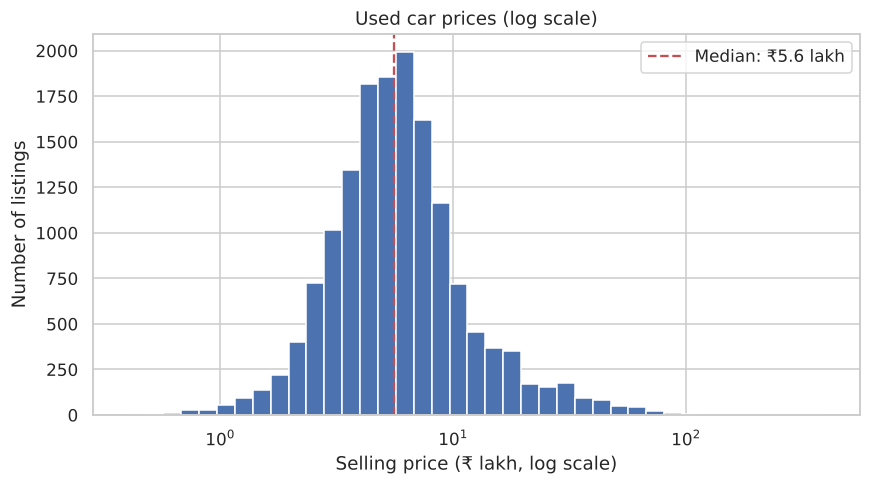

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(np.log10(df["price_lakh"].min()), np.log10(df["price_lakh"].max()), 40)
ax.hist(df["price_lakh"], bins=bins, color="#4C72B0")
ax.set_xscale("log")
ax.axvline(df["price_lakh"].median(), color="#C44E52", ls="--", label=f"Median: ₹{df['price_lakh'].median():.1f} lakh")
ax.set_title("Used car prices (log scale)")
ax.set_xlabel("Selling price (₹ lakh, log scale)")
ax.set_ylabel("Number of listings")
ax.legend()
plt.savefig("charts/01_price_distribution.png", bbox_inches="tight")
plt.show()

### Median price by age of the car

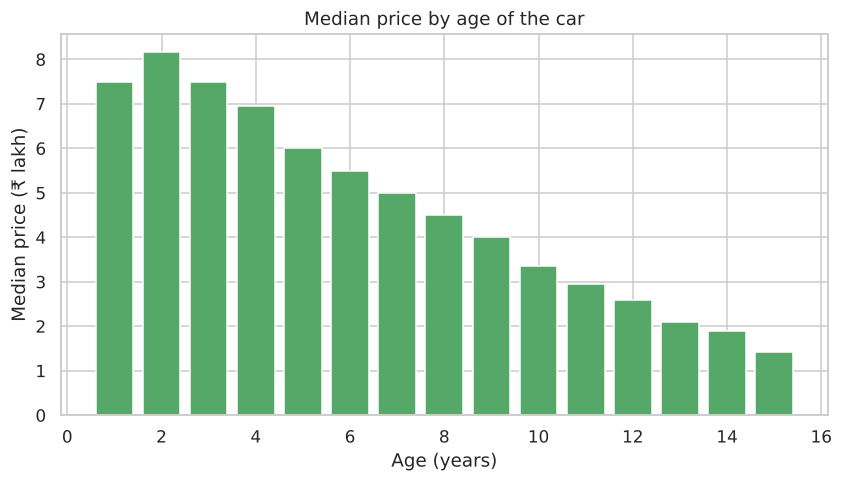

In [24]:
by_age = df.groupby("vehicle_age")["price_lakh"].agg(["median", "count"]).reset_index()
by_age = by_age[(by_age["vehicle_age"] <= 15) & (by_age["count"] >= 30)]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(by_age["vehicle_age"], by_age["median"], color="#55A868")
ax.set_title("Median price by age of the car")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Median price (₹ lakh)")
plt.savefig("charts/02_median_price_by_age.png", bbox_inches="tight")
plt.show()

### Yearly value loss by model (same model compared across ages)

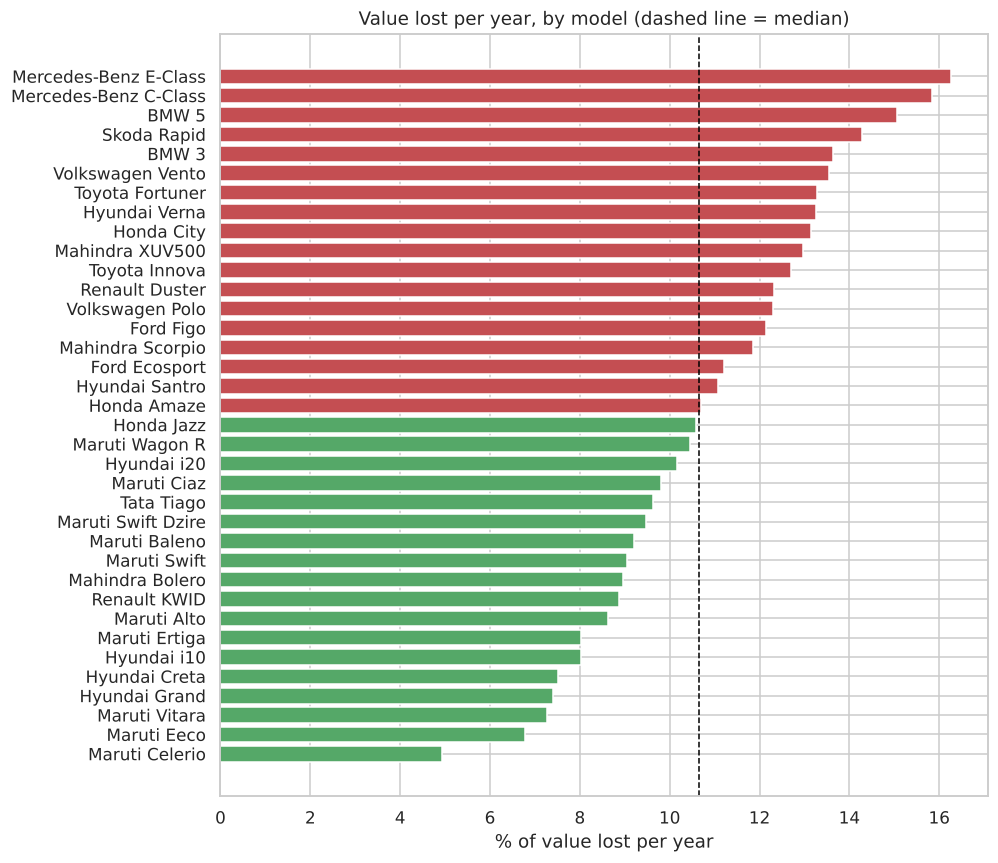

In [25]:
d = dep.sort_values("annual_value_loss_pct")
fig, ax = plt.subplots(figsize=(9, 9))
colors = ["#55A868" if v < dep["annual_value_loss_pct"].median() else "#C44E52" for v in d["annual_value_loss_pct"]]
ax.barh(d["car_name"], d["annual_value_loss_pct"], color=colors)
ax.axvline(dep["annual_value_loss_pct"].median(), color="black", ls="--", lw=1)
ax.set_title("Value lost per year, by model (dashed line = median)")
ax.set_xlabel("% of value lost per year")
plt.savefig("charts/03_value_loss_by_model.png", bbox_inches="tight")
plt.show()

### Scatter plot 1: price vs age
Each dot is one car. The log scale on the price axis makes cheap and expensive cars readable together.

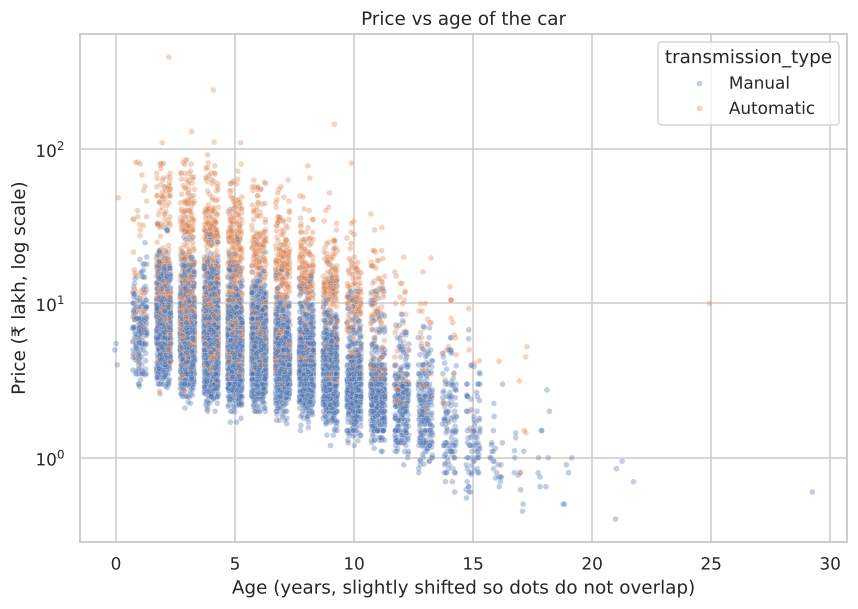

In [26]:
rng = np.random.default_rng(1)
plot_df = df.copy()
plot_df["age_jitter"] = plot_df["vehicle_age"] + rng.uniform(-0.3, 0.3, len(plot_df))
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="age_jitter", y="price_lakh", hue="transmission_type", alpha=0.35, s=14, ax=ax)
ax.set_yscale("log")
ax.set_title("Price vs age of the car")
ax.set_xlabel("Age (years, slightly shifted so dots do not overlap)")
ax.set_ylabel("Price (₹ lakh, log scale)")
plt.savefig("charts/04_scatter_price_age.png", bbox_inches="tight")
plt.show()

### Scatter plot 2: price vs kilometres driven

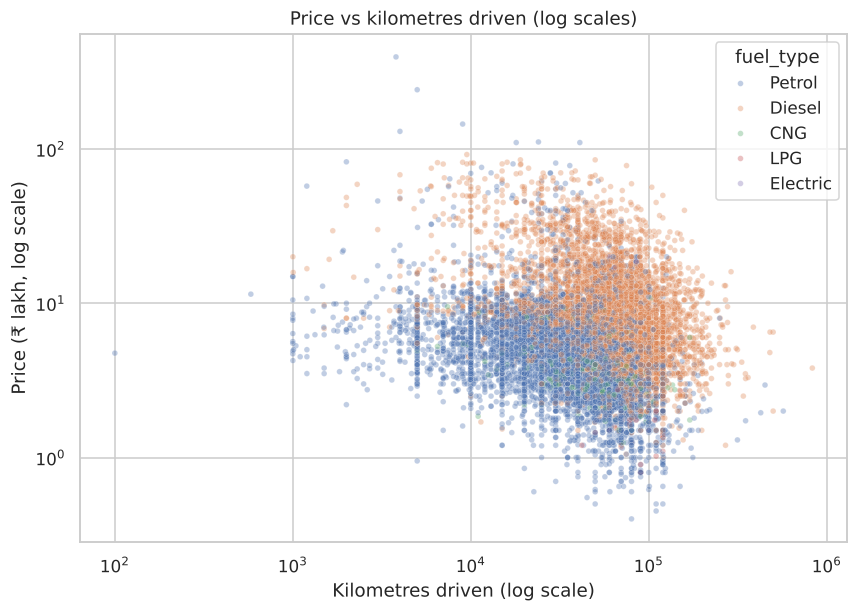

Spearman correlation between km driven and price: -0.17


In [27]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="km_driven", y="price_lakh", hue="fuel_type", hue_order=["Petrol", "Diesel", "CNG", "LPG", "Electric"], alpha=0.35, s=14, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Price vs kilometres driven (log scales)")
ax.set_xlabel("Kilometres driven (log scale)")
ax.set_ylabel("Price (₹ lakh, log scale)")
plt.savefig("charts/05_scatter_price_km.png", bbox_inches="tight")
plt.show()
rho_km, _ = spearmanr(df["km_driven"], df["selling_price"])
print(f"Spearman correlation between km driven and price: {rho_km:.2f}")

### Scatter plot 3: price vs engine power

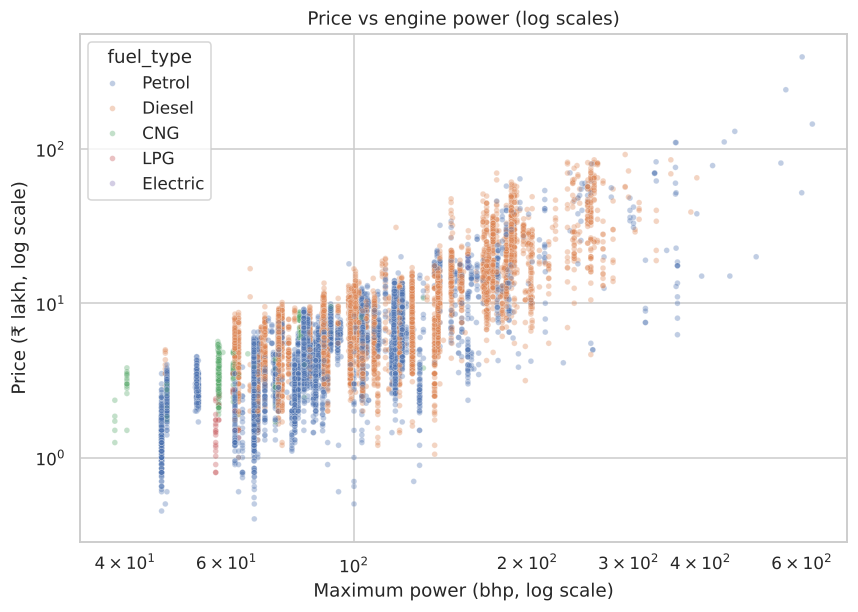

Spearman correlation between power and price: 0.72


In [28]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="max_power", y="price_lakh", hue="fuel_type", hue_order=["Petrol", "Diesel", "CNG", "LPG", "Electric"], alpha=0.35, s=14, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Price vs engine power (log scales)")
ax.set_xlabel("Maximum power (bhp, log scale)")
ax.set_ylabel("Price (₹ lakh, log scale)")
plt.savefig("charts/06_scatter_price_power.png", bbox_inches="tight")
plt.show()
rho_pw, _ = spearmanr(df["max_power"], df["selling_price"])
print(f"Spearman correlation between power and price: {rho_pw:.2f}")

### Scatter plot 4: do bigger engines use more fuel?
Only petrol and diesel cars, because CNG and LPG mileage is in a different unit.

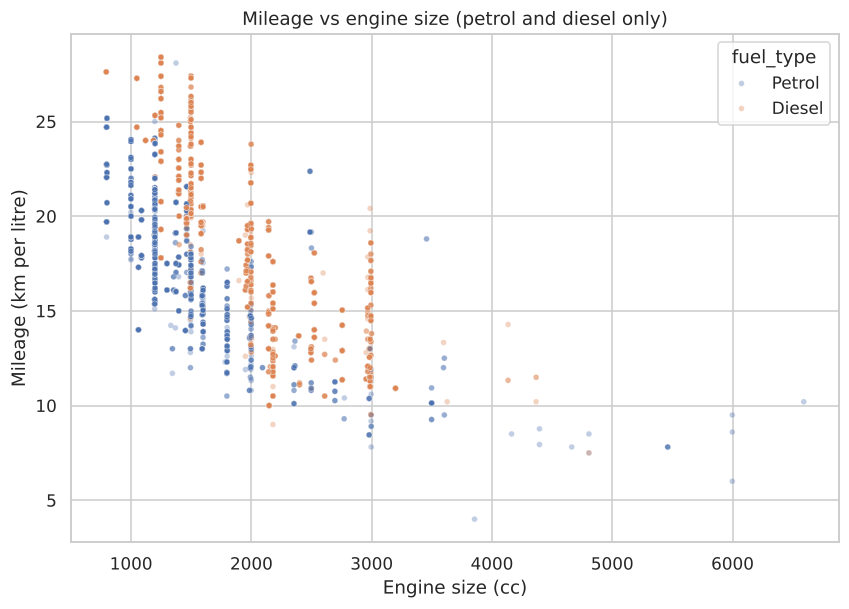

Spearman correlation between engine size and mileage: -0.49


In [29]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=mileage_df, x="engine", y="mileage", hue="fuel_type", alpha=0.35, s=14, ax=ax)
ax.set_title("Mileage vs engine size (petrol and diesel only)")
ax.set_xlabel("Engine size (cc)")
ax.set_ylabel("Mileage (km per litre)")
plt.savefig("charts/07_scatter_mileage_engine.png", bbox_inches="tight")
plt.show()
rho_me, _ = spearmanr(mileage_df["engine"], mileage_df["mileage"])
print(f"Spearman correlation between engine size and mileage: {rho_me:.2f}")

### Median price of the most common brands

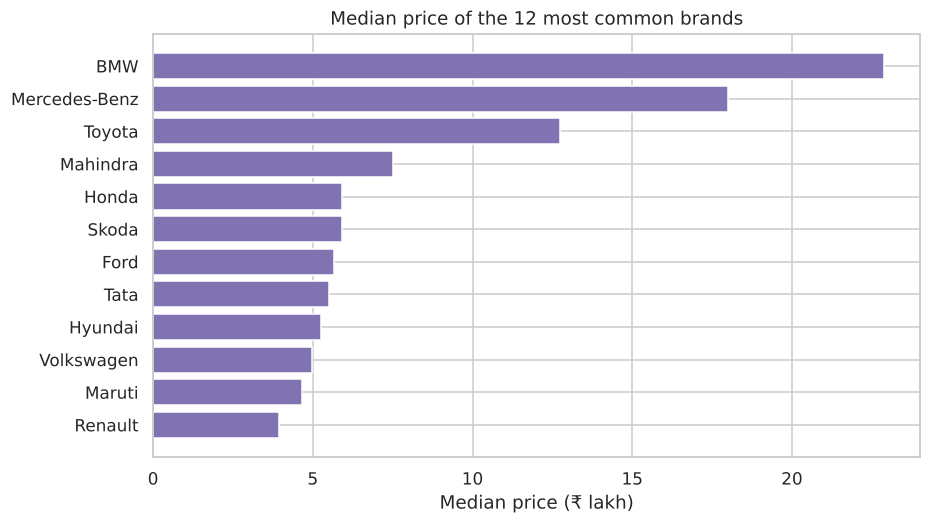

In [30]:
top_brands = df["brand"].value_counts().head(12).index
bp = df[df["brand"].isin(top_brands)].groupby("brand")["price_lakh"].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(bp.index, bp.values, color="#8172B2")
ax.set_title("Median price of the 12 most common brands")
ax.set_xlabel("Median price (₹ lakh)")
plt.savefig("charts/08_brand_median_price.png", bbox_inches="tight")
plt.show()

### Raw gap vs same-model gap

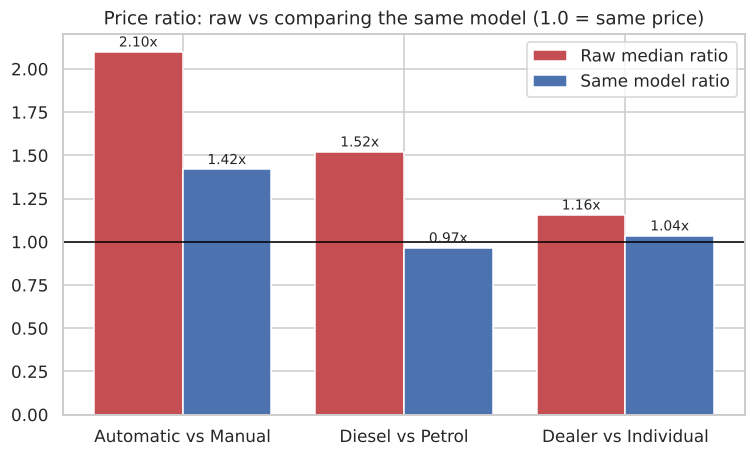

In [31]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(gaps))
ax.bar(x - 0.2, gaps["raw_price_ratio"], width=0.4, label="Raw median ratio", color="#C44E52")
ax.bar(x + 0.2, gaps["same_model_price_ratio"], width=0.4, label="Same model ratio", color="#4C72B0")
ax.axhline(1, color="black", lw=1)
ax.set_xticks(x); ax.set_xticklabels(gaps["comparison"])
for i, r in gaps.iterrows():
    ax.text(i - 0.2, r["raw_price_ratio"] + 0.03, f"{r['raw_price_ratio']:.2f}x", ha="center", fontsize=9)
    ax.text(i + 0.2, r["same_model_price_ratio"] + 0.03, f"{r['same_model_price_ratio']:.2f}x", ha="center", fontsize=9)
ax.set_title("Price ratio: raw vs comparing the same model (1.0 = same price)")
ax.legend()
plt.savefig("charts/09_raw_vs_same_model_gap.png", bbox_inches="tight")
plt.show()

### Correlation heatmap

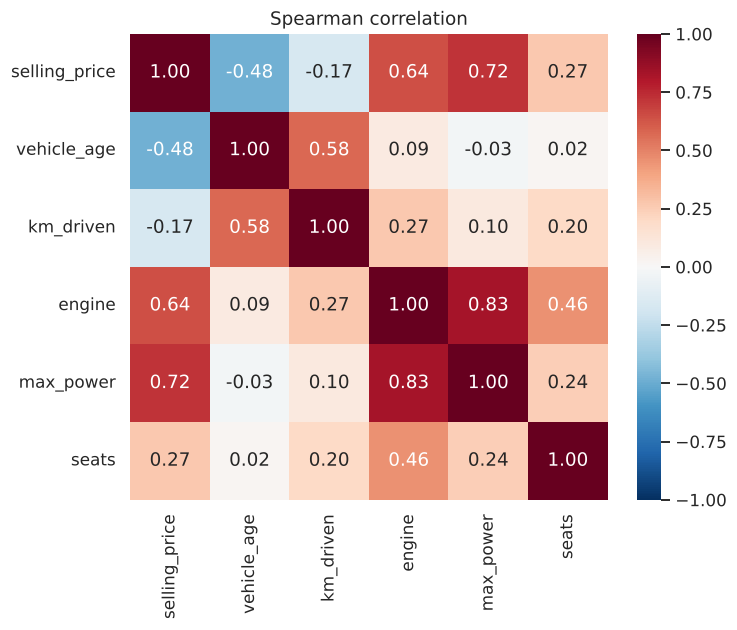

In [32]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
plt.savefig("charts/10_correlation_heatmap.png", bbox_inches="tight")
plt.show()

### Interactive chart (Plotly)
Hover over a dot to see the car. GitHub does not show interactive Plotly output inside notebooks, so I also save it as an HTML file in the `charts` folder (download it and open it in a browser).

In [33]:
sample = df.sample(4000, random_state=1)
fig = px.scatter(sample, x="max_power", y="selling_price", color="fuel_type",
                 hover_data=["car_name", "vehicle_age", "km_driven", "transmission_type"],
                 log_x=True, log_y=True, opacity=0.6,
                 title="Price vs engine power (random sample of 4,000 cars)")
fig.update_layout(xaxis_title="Maximum power (bhp)", yaxis_title="Selling price (₹)")
fig.write_html("charts/interactive_price_vs_power.html", include_plotlyjs="cdn")
fig.show()

In [34]:
med_by_age = df.groupby("vehicle_age")["selling_price"].median()
dep_s = dep.sort_values("annual_value_loss_pct")
vc = df["brand"].value_counts()
rho_age, _ = spearmanr(df["vehicle_age"], df["selling_price"])
rho_eng, _ = spearmanr(df["engine"], df["selling_price"])

K = {
    "raw_rows": int(len(raw)),
    "brand_fixed": int(log[1]["rows_changed"]),
    "duplicates_removed": int(log[2]["rows_removed"]),
    "zero_seats_removed": int(log[3]["rows_removed"]),
    "km_removed": int(log[4]["rows_removed"]),
    "clean_rows": int(len(df)),
    "pct_rows_kept": float(len(df) / len(raw) * 100),
    "brands": int(df["brand"].nunique()),
    "models": int(df["car_name"].nunique()),
    "price_median": float(df["selling_price"].median()),
    "price_mean": float(df["selling_price"].mean()),
    "price_max": float(df["selling_price"].max()),
    "cars_over_1_crore": int((df["selling_price"] > 10_000_000).sum()),
    "median_age": float(df["vehicle_age"].median()),
    "median_km": float(df["km_driven"].median()),
    "pct_manual": float((df["transmission_type"] == "Manual").mean() * 100),
    "pct_dealer": float((df["seller_type"] != "Individual").mean() * 100),
    "pct_petrol": float((df["fuel_type"] == "Petrol").mean() * 100),
    "pct_diesel": float((df["fuel_type"] == "Diesel").mean() * 100),
    "top2_brands": [str(vc.index[0]), str(vc.index[1])],
    "top2_brands_pct": float(vc.iloc[:2].sum() / len(df) * 100),
    "median_price_age_0": float(med_by_age.get(0)), "median_price_age_2": float(med_by_age.get(2)),
    "median_price_age_5": float(med_by_age.get(5)), "median_price_age_10": float(med_by_age.get(10)),
    "dep_models": int(len(dep)),
    "dep_median": float(dep["annual_value_loss_pct"].median()),
    "dep_best_model": str(dep_s.iloc[0]["car_name"]), "dep_best": float(dep_s.iloc[0]["annual_value_loss_pct"]),
    "dep_worst_model": str(dep_s.iloc[-1]["car_name"]), "dep_worst": float(dep_s.iloc[-1]["annual_value_loss_pct"]),
    "dep_best3": [(str(r.car_name), round(float(r.annual_value_loss_pct), 1)) for r in dep_s.head(3).itertuples()],
    "dep_worst3": [(str(r.car_name), round(float(r.annual_value_loss_pct), 1)) for r in dep_s.tail(3).iloc[::-1].itertuples()],
    "gap_auto_raw": float(gaps.loc[0, "raw_price_ratio"]), "gap_auto_same": float(gaps.loc[0, "same_model_price_ratio"]), "gap_auto_n": int(gaps.loc[0, "models_compared"]),
    "gap_diesel_raw": float(gaps.loc[1, "raw_price_ratio"]), "gap_diesel_same": float(gaps.loc[1, "same_model_price_ratio"]), "gap_diesel_n": int(gaps.loc[1, "models_compared"]),
    "gap_dealer_raw": float(gaps.loc[2, "raw_price_ratio"]), "gap_dealer_same": float(gaps.loc[2, "same_model_price_ratio"]), "gap_dealer_n": int(gaps.loc[2, "models_compared"]),
    "rho_price_age": float(rho_age), "rho_price_km": float(rho_km), "rho_price_power": float(rho_pw),
    "rho_price_engine": float(rho_eng), "rho_mileage_engine": float(rho_me),
    "electric_rows": int((df["fuel_type"] == "Electric").sum()),
    "median_km_per_year": float(df["km_per_year"].median()),
}
json.dump(K, open("outputs/key_numbers.json", "w"), indent=2)
print(json.dumps(K, indent=1)[:3000])

{
 "raw_rows": 15411,
 "brand_fixed": 2,
 "duplicates_removed": 167,
 "zero_seats_removed": 2,
 "km_removed": 13,
 "clean_rows": 15229,
 "pct_rows_kept": 98.8190253714879,
 "brands": 31,
 "models": 120,
 "price_median": 556000.0,
 "price_mean": 774551.5053516318,
 "price_max": 39500000.0,
 "cars_over_1_crore": 7,
 "median_age": 6.0,
 "median_km": 50000.0,
 "pct_manual": 79.34204478297984,
 "pct_dealer": 63.16895396940049,
 "pct_petrol": 49.583032372447306,
 "pct_diesel": 48.13842011950884,
 "top2_brands": [
  "Maruti",
  "Hyundai"
 ],
 "top2_brands_pct": 51.75651717118656,
 "median_price_age_0": 525000.0,
 "median_price_age_2": 816000.0,
 "median_price_age_5": 600000.0,
 "median_price_age_10": 335500.0,
 "dep_models": 36,
 "dep_median": 10.641902754295359,
 "dep_best_model": "Maruti Celerio",
 "dep_best": 4.920717927081064,
 "dep_worst_model": "Mercedes-Benz E-Class",
 "dep_worst": 16.265798465058733,
 "dep_best3": [
  [
   "Maruti Celerio",
   4.9
  ],
  [
   "Maruti Eeco",
   6.8
  ]

## 7. Findings

**The market**
- After cleaning there are 15,229 listings from 31 brands and 120 models. The median car is 6 years old, has 50,000 km on it and costs ₹5.6 lakh. The average is ₹7.7 lakh, pulled up by a few luxury cars (the most expensive is ₹3.95 crore).
- Maruti and Hyundai together are 52% of all listings. 79% of the cars are manual, and 50% are petrol and 48% diesel.

**How fast cars lose value**
- Comparing the same model at different ages, cars lose about **11% of their value per year** (median of 36 models).
- It varies a lot by model. Slowest: Maruti Celerio (4.9%), Maruti Eeco (6.8%), Maruti Vitara (7.3%). Fastest: Mercedes-Benz E-Class (16.3%), Mercedes-Benz C-Class (15.8%), BMW 5 (15.1%). Small mass-market cars hold value better. Premium German cars lose it fastest.
- Raw medians by age: ₹8.2 lakh at 2 years, ₹6.0 lakh at 5 years and ₹3.4 lakh at 10 years.

**What goes with price**
- Engine power has the strongest link with price (correlation 0.72), then engine size (0.64). Age is negative (-0.48).
- Kilometres driven matters much less than age (-0.17). In this data, how old a car is tells more about its price than how far it has been driven.
- Bigger engines have lower mileage (-0.49 correlation between engine size and km per litre, petrol and diesel only).

**Are automatic, diesel and dealer cars really more expensive?**
- **Automatic:** the raw median is 2.1x the manual price, but for the same model it is only about 1.42x (16 models compared). Most of the raw gap comes from automatic cars being bigger, pricier models.
- **Diesel:** the raw median is 1.52x petrol, but for the same model it is about 0.97x (16 models). I see no clear diesel premium in these models.
- **Dealer:** the raw median is 1.16x individual sellers, and 1.04x for the same model (29 models). The dealer price difference is small.

**Limits of this analysis**
- These are listing (asking) prices, not final sale prices.
- No city, condition, accident history or variant (for example base or top model) in the data, and these affect price a lot.
- The same-model comparison does not control for age and kilometres, so it is a closer comparison, not proof that transmission or fuel causes the price change.
- 4 rows are labelled Electric but all are the Toyota Camry with a petrol-type engine size. I think the label is wrong and kept them out of fuel comparisons.
- Removing exact duplicates assumes they are the same listing added twice.

## 8. Save the cleaned files

In [35]:
export_cols = ["car_name", "brand", "model", "vehicle_age", "km_driven", "km_per_year", "seller_type", "fuel_type",
               "transmission_type", "mileage", "engine", "max_power", "seats", "selling_price", "price_lakh"]
df[export_cols].to_csv("outputs/cars_cleaned.csv", index=False)
dep.to_csv("outputs/value_loss_by_model.csv", index=False)
gaps.to_csv("outputs/raw_vs_same_model_gap.csv", index=False)
pd.DataFrame(log).to_csv("outputs/cleaning_log.csv", index=False)
print("Saved:", os.listdir("outputs"))

Saved: ['value_loss_by_model.csv', 'cleaning_log.csv', 'key_numbers.json', 'raw_vs_same_model_gap.csv', 'cars_cleaned.csv']
